# Descomposición de las series temporales de la cartera: Caterpillar, Merck y Microsoft

Este notebook descompone el precio de cada uno de los tres activos de la cartera en **tendencia**, **estacionalidad** y **residuo**, y justifica con los datos las dos decisiones de las que depende la descomposición:

1. **El modelo** (aditivo o multiplicativo), elegido activo por activo.
2. **El periodo estacional**, elegido según la frecuencia de los datos y comprobando si existe estacionalidad.

| Activo | Ticker | Sector |
|---|---|---|
| Caterpillar | CAT | Industrial (maquinaria) |
| Merck & Co. | MRK | Salud (farmacéutica) |
| Microsoft | MSFT | Tecnología |

**Datos:** `Datos/Transformados/dowjones_diario_2016_2025.csv`, el mismo archivo que usan `Analisis_descriptivo.ipynb` y `Procesamiento_series_temporales.ipynb`. Se usa el precio de cierre (`close`).

**Estructura**

1. Datos y frecuencia
2. Elección del modelo: aditivo o multiplicativo
3. Elección del periodo y evidencia de estacionalidad
4. Descomposición de cada activo (un gráfico por activo)
5. Diagnóstico del residuo
6. Tabla resumen
7. Interpretación de cada activo
8. Conclusión comparativa y limitaciones
9. Comprobación de los criterios de aceptación

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import acf

warnings.filterwarnings("ignore", category=FutureWarning)

# Estilo común de los gráficos (CLAUDE.md): se busca la raíz del proyecto, que es la carpeta que contiene
# packages/bbva_graficos.py, subiendo desde la carpeta en la que se ejecuta el notebook
RAIZ_PROYECTO = next((d for d in [Path.cwd(), *Path.cwd().parents] if (d / "packages" / "bbva_graficos.py").exists()), None)
if RAIZ_PROYECTO is None:
    raise FileNotFoundError(f"No se encuentra packages/bbva_graficos.py ni en {Path.cwd()} ni en sus carpetas superiores. "
                            "Copia la carpeta packages/ en la raíz del proyecto.")
sys.path.insert(0, str(RAIZ_PROYECTO))
from packages.bbva_graficos import (BBVA, anotar_fuente, configurar_graficos, fmt_es, formato_eje_pct,
                                    guardar_mpl, pct_es)
configurar_graficos(carpeta=str(RAIZ_PROYECTO / "Graficos"))
print("Raíz del proyecto:", RAIZ_PROYECTO)

FileNotFoundError: No se encuentra packages/bbva_graficos.py ni en c:\RETOS BDATA 3\26_27_R09_Azul_Claro ni en sus carpetas superiores. Copia la carpeta packages/ en la raíz del proyecto.

In [ ]:
# ---------------------------------------------------------------- Parámetros
RUTA_DATOS = RAIZ_PROYECTO / "Datos" / "Transformados" / "dowjones_diario_2016_2025.csv"
RUTA_RESULTADOS = RAIZ_PROYECTO / "Datos" / "Transformados"

ACTIVOS = {"CAT": "Caterpillar", "MRK": "Merck", "MSFT": "Microsoft"}
ALFA = 0.05                 # nivel de significación de todos los contrastes
PERIODO = 12                # periodo estacional candidato en la serie mensual (meses por año)
RETARDOS_ACF = 36           # tres años de retardos en los correlogramas mensuales
RETARDOS_LJUNG_BOX = 12     # un año de retardos en el test de Ljung-Box del residuo

# Alias de fin de mes: "ME" desde pandas 2.2, "M" en versiones anteriores
FREC_MES = "ME" if tuple(int(x) for x in pd.__version__.split(".")[:2]) >= (2, 2) else "M"

# Colores de la paleta BBVA
PRINCIPAL, MEDIO, CIELO, AGUAMARINA, MARINO = (BBVA[k] for k in ("principal", "medio", "cielo", "aguamarina", "marino"))
GRIS = BBVA["gris"]
FUENTE = "Fuente: elaboración propia a partir de los cierres diarios del Dow Jones (2016-2025)."
pd.set_option("display.width", 200)


def eje_anios(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


def fmt_p(p):
    # p-valor en formato español: "= 0,025" o "< 0,001"
    return "< 0,001" if p < 0.001 else f"= {fmt_es(p, 3)}"


def cerrar_grafico(fig, nombre):
    # Añade la fuente, guarda la figura en Graficos/<nombre>.png y la muestra
    anotar_fuente(fig, FUENTE)
    guardar_mpl(fig, nombre)
    plt.show()

## 1. Datos y frecuencia

Antes de descomponer hay que comprobar cuatro cosas:

- **Frecuencia.** Los datos son diarios, pero solo hay sesiones en días hábiles de la bolsa de Nueva York, así que el espaciado no es regular (fines de semana y festivos).
- **Valores válidos.** No debe haber huecos y todos los precios tienen que ser positivos; si no, el modelo multiplicativo no se puede aplicar.
- **Número de observaciones y de ciclos completos.**
- **Cambios de fuente.** El archivo mezcla datos de Yahoo Finance y de un CSV externo (columna `fuente`), así que se comprueba que no haya saltos de precio en las fechas en que cambia la fuente.

In [ ]:
df = pd.read_csv(RUTA_DATOS, parse_dates=["date"])
df = df[df["symbol"].isin(ACTIVOS)].sort_values(["symbol", "date"])
precios = df.pivot(index="date", columns="symbol", values="close")[list(ACTIVOS)]

# Espaciado entre sesiones consecutivas (días naturales)
saltos = precios.index.to_series().diff().dt.days.value_counts().sort_index()
print(f"Sesiones: {len(precios)} | de {precios.index[0].date()} a {precios.index[-1].date()}")
print("Días naturales entre sesiones consecutivas:", saltos.astype(int).to_dict())
print("Sesiones por año:", precios.groupby(precios.index.year).size().to_dict())
print("Valores ausentes por activo:", precios.isna().sum().to_dict())
print("Precio mínimo por activo (USD):", precios.min().round(2).to_dict())

# Rentabilidad diaria en los días en que cambia la fuente de los datos: un salto artificial aparecería aquí
rent_diaria = np.log(precios).diff()
for t in ACTIVOS:
    d = df[df["symbol"] == t].set_index("date")["fuente"]
    cambios = d.index[(d != d.shift()) & d.shift().notna()]
    print(f"{t}: {len(cambios)} cambios de fuente; |rentabilidad| máxima en esos días = "
          f"{rent_diaria.loc[cambios, t].abs().max():.4f} (máxima de toda la serie: {rent_diaria[t].abs().max():.4f})")

Sesiones: 2514 | de 2016-01-04 a 2025-12-31
Días naturales entre sesiones consecutivas: {1.0: 1966, 2.0: 26, 3.0: 453, 4.0: 68}
Sesiones por año: {2016: 252, 2017: 251, 2018: 251, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 250}
Valores ausentes por activo: {'CAT': 0, 'MRK': 0, 'MSFT': 0}
Precio mínimo por activo (USD): {'CAT': 57.91, 'MRK': 46.36, 'MSFT': 48.43}
CAT: 8 cambios de fuente; |rentabilidad| máxima en esos días = 0.0195 (máxima de toda la serie: 0.1534)
MRK: 10 cambios de fuente; |rentabilidad| máxima en esos días = 0.0318 (máxima de toda la serie: 0.1038)
MSFT: 10 cambios de fuente; |rentabilidad| máxima en esos días = 0.0354 (máxima de toda la serie: 0.1595)


**Por qué se descompone la serie mensual y no la diaria**

`seasonal_decompose` estima la estacionalidad como la media de los valores que ocupan la misma posición dentro de cada ciclo (posición 1, posición 2, …). Por eso necesita que un periodo tenga siempre el mismo número de observaciones y que cada posición corresponda siempre al mismo momento del calendario. Con la serie diaria eso no se cumple:

- **Periodo anual (252 sesiones).** El número de sesiones por año cambia (entre 250 y 253, según la salida anterior), así que la posición 1 del ciclo no cae siempre en el mismo día del año y el patrón se va desplazando. Además, la media móvil de 252 sesiones pierde medio año de datos en cada extremo.
- **Periodo semanal (5 sesiones).** Cada festivo desplaza la posición dentro del ciclo de 5: tras un festivo, la "posición 1" deja de ser el lunes. El efecto del día de la semana se contrasta directamente en el apartado 3.

Por eso la descomposición se hace sobre el **precio de cierre del último día de cada mes**. Así la frecuencia es regular (12 observaciones por año) y cada posición del ciclo es siempre el mismo mes. Se usa el último cierre, y no la media del mes, porque es el precio observado realmente en una fecha concreta. La media mensual suavizaría la serie y repartiría el ruido entre los componentes.

In [ ]:
precios_mes = precios.resample(FREC_MES).last()
n_meses = len(precios_mes)
anios_completos = int((precios_mes.groupby(precios_mes.index.year).size() == 12).sum())
print(f"Observaciones mensuales: {n_meses} ({precios_mes.index[0]:%Y-%m} a {precios_mes.index[-1]:%Y-%m})")
print(f"Ciclos anuales completos: {anios_completos} (seasonal_decompose exige al menos 2)")
print(f"La media móvil centrada de {PERIODO} meses pierde {PERIODO // 2} observaciones en cada extremo: "
      f"la tendencia y el residuo se estiman en {n_meses - PERIODO} meses, y cada índice estacional es la media "
      f"de {(n_meses - PERIODO) // PERIODO} valores")
print(precios_mes.describe().round(2).to_string())

Observaciones mensuales: 120 (2016-01 a 2025-12)
Ciclos anuales completos: 10 (seasonal_decompose exige al menos 2)
La media móvil centrada de 12 meses pierde 6 observaciones en cada extremo: la tendencia y el residuo se estiman en 108 meses, y cada índice estacional es la media de 9 valores
symbol     CAT     MRK    MSFT
count   120.00  120.00  120.00
mean    205.93   81.20  230.72
std     111.65   20.73  139.23
min      62.24   47.91   49.87
25%     126.94   62.85  100.89
50%     176.13   77.68  228.57
75%     247.22   93.89  332.69
max     577.26  131.95  533.50


## 2. Elección del modelo: aditivo o multiplicativo

- **Aditivo:** $Y_t = T_t + S_t + R_t$. Las oscilaciones estacionales y el residuo tienen un tamaño **en USD** que no depende del nivel.
- **Multiplicativo:** $Y_t = T_t \cdot S_t \cdot R_t$. Las oscilaciones son un **porcentaje** del nivel, así que crecen en USD cuando el precio sube. Es equivalente a una descomposición aditiva del logaritmo. Solo es válido si todos los valores son estrictamente positivos.

El modelo se elige **para cada activo por separado** con un criterio previo de validez y dos criterios de datos:

0. **Validez matemática:** si algún precio es ≤ 0, solo puede usarse el aditivo.
1. **Amplitud frente a nivel (por años).** Para cada año se calcula el nivel medio del precio y la desviación típica de las variaciones mensuales en USD, y se correlacionan los 10 pares con Spearman. Se usan años sin solapamiento para que las observaciones sean independientes. Si la amplitud crece con el nivel (ρ > 0 significativo), el modelo es multiplicativo.
2. **Residuo frente a tendencia.** Se descompone con los dos modelos y se mide la correlación de Spearman entre la tendencia y el tamaño del residuo. En un modelo adecuado, el tamaño del residuo no debería depender del nivel de la tendencia.

**Regla de decisión:** multiplicativo si los dos criterios indican que la amplitud crece con el nivel; aditivo si ninguno lo indica. Si solo uno lo indica, se elige el modelo cuyo residuo depende menos de la tendencia y se avisa de que la evidencia es parcial.

In [ ]:
def amplitud_por_anio(serie_mensual):
    # Nivel medio y desviación típica de las variaciones mensuales (USD) de cada año natural
    return pd.DataFrame({
        "nivel_usd": serie_mensual.groupby(serie_mensual.index.year).mean(),
        "amplitud_usd": serie_mensual.diff().groupby(serie_mensual.index.year).std(),
    })


def residuo_relativo(descomposicion, modelo):
    # Tamaño del residuo comparable entre modelos: en USD (aditivo) o en desviación porcentual (multiplicativo)
    return descomposicion.resid.abs() if modelo == "additive" else (descomposicion.resid - 1).abs()


def elegir_modelo(serie_mensual):
    resultado = {"precio_min_usd": serie_mensual.min(),
                 "max_entre_min": serie_mensual.max() / serie_mensual.min()}
    if serie_mensual.min() <= 0:
        resultado.update(modelo="additive", decision="Solo es posible el aditivo (hay valores <= 0)")
        return resultado

    # Criterio 1: amplitud frente a nivel, por años
    anual = amplitud_por_anio(serie_mensual)
    rho1, p1 = stats.spearmanr(anual["nivel_usd"], anual["amplitud_usd"])
    resultado.update(rho_amplitud_nivel=rho1, p_amplitud_nivel=p1)

    # Criterio 2: dependencia del tamaño del residuo respecto a la tendencia, con cada modelo
    for modelo, sufijo in [("additive", "aditivo"), ("multiplicative", "multiplicativo")]:
        d = seasonal_decompose(serie_mensual, model=modelo, period=PERIODO)
        datos = pd.DataFrame({"tendencia": d.trend, "residuo": residuo_relativo(d, modelo)}).dropna()
        rho, p = stats.spearmanr(datos["tendencia"], datos["residuo"])
        resultado.update({f"rho_resid_{sufijo}": rho, f"p_resid_{sufijo}": p})

    crece_1 = (rho1 > 0) and (p1 < ALFA)
    crece_2 = (resultado["rho_resid_aditivo"] > 0) and (resultado["p_resid_aditivo"] < ALFA)
    if crece_1 and crece_2:
        modelo, decision = "multiplicative", "Multiplicativo: los dos criterios indican que la amplitud crece con el nivel"
    elif not crece_1 and not crece_2:
        modelo, decision = "additive", "Aditivo: ningún criterio indica que la amplitud crezca con el nivel"
    else:
        mejor = abs(resultado["rho_resid_multiplicativo"]) < abs(resultado["rho_resid_aditivo"])
        modelo = "multiplicative" if mejor else "additive"
        decision = f"{'Multiplicativo' if mejor else 'Aditivo'} (evidencia parcial: solo un criterio es significativo)"
    resultado.update(modelo=modelo, decision=decision)
    return resultado


eleccion_modelo = pd.DataFrame({t: elegir_modelo(precios_mes[t]) for t in ACTIVOS}).T
MODELO = eleccion_modelo["modelo"].to_dict()
columnas = ["precio_min_usd", "max_entre_min", "rho_amplitud_nivel", "p_amplitud_nivel",
            "rho_resid_aditivo", "p_resid_aditivo", "rho_resid_multiplicativo", "p_resid_multiplicativo"]
print(eleccion_modelo[columnas].astype(float).round(3).to_string())
print()
for t in ACTIVOS:
    print(f"{t}: {eleccion_modelo.loc[t, 'decision']}")
for t in ACTIVOS:
    print(f"\n{t}: nivel y amplitud por año (USD)")
    print(amplitud_por_anio(precios_mes[t]).round(1).T.to_string())

      precio_min_usd  max_entre_min  rho_amplitud_nivel  p_amplitud_nivel  rho_resid_aditivo  p_resid_aditivo  rho_resid_multiplicativo  p_resid_multiplicativo
CAT            62.24          9.275               0.952             0.000              0.500            0.000                     0.271                   0.005
MRK            47.91          2.754               0.697             0.025              0.329            0.001                     0.143                   0.139
MSFT           49.87         10.698               0.939             0.000              0.420            0.000                     0.264                   0.006

CAT: Multiplicativo: los dos criterios indican que la amplitud crece con el nivel
MRK: Multiplicativo: los dos criterios indican que la amplitud crece con el nivel
MSFT: Multiplicativo: los dos criterios indican que la amplitud crece con el nivel

CAT: nivel y amplitud por año (USD)
date          2016   2017   2018   2019   2020   2021   2022   2023   2024 

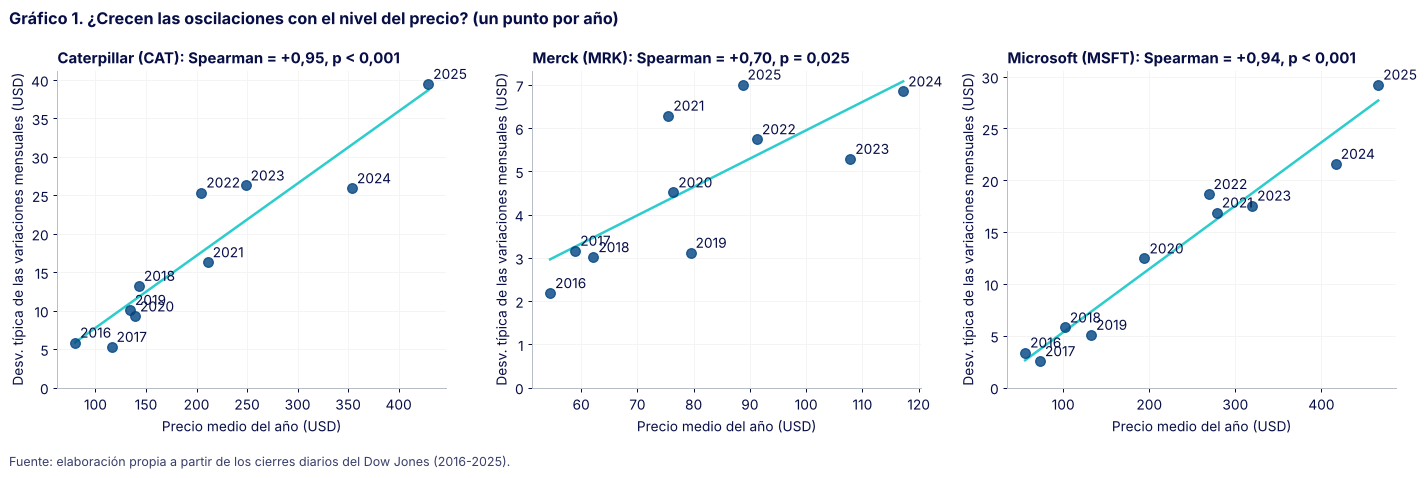

In [ ]:
fig, ejes = plt.subplots(1, 3, figsize=(16, 5))
for ax, t in zip(ejes, ACTIVOS):
    anual = amplitud_por_anio(precios_mes[t])
    ax.scatter(anual["nivel_usd"], anual["amplitud_usd"], s=60, color=PRINCIPAL, alpha=0.8, zorder=3)
    for anio, fila in anual.iterrows():
        ax.annotate(str(anio), (fila["nivel_usd"], fila["amplitud_usd"]), xytext=(4, 4),
                    textcoords="offset points", color=MARINO, fontsize=11)
    pendiente, corte = np.polyfit(anual["nivel_usd"], anual["amplitud_usd"], 1)
    x = np.linspace(anual["nivel_usd"].min(), anual["nivel_usd"].max(), 50)
    ax.plot(x, corte + pendiente * x, color=AGUAMARINA, lw=2)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Precio medio del año (USD)")
    ax.set_ylabel("Desv. típica de las variaciones mensuales (USD)")
    rho = eleccion_modelo.loc[t, "rho_amplitud_nivel"]
    p = eleccion_modelo.loc[t, "p_amplitud_nivel"]
    ax.set_title(f"{ACTIVOS[t]} ({t}): Spearman = {fmt_es(rho, 2, signo=True)}, p {fmt_p(p)}")
fig.suptitle("Gráfico 1. ¿Crecen las oscilaciones con el nivel del precio? (un punto por año)", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "descomposicion_01_amplitud_frente_a_nivel")

**Resultado: modelo multiplicativo para los tres activos, aunque la evidencia no es igual de fuerte en todos.**

- **Caterpillar.** Su precio máximo es 9,3 veces el mínimo. La desviación típica de las variaciones mensuales pasa de 5,8 USD en 2016 a 39,5 USD en 2025 y crece casi en el mismo orden que el nivel (Spearman = 0,95; p < 0,001). Con el modelo aditivo, el tamaño del residuo aumenta con la tendencia (ρ = 0,50); con el multiplicativo esa dependencia baja a ρ = 0,27.
- **Microsoft.** Es el caso más claro: el máximo es 10,7 veces el mínimo, la amplitud pasa de 3,4 a 29,2 USD (ρ = 0,94; p < 0,001) y el residuo aditivo depende de la tendencia (ρ = 0,42), mucho más que el multiplicativo (ρ = 0,26).
- **Merck.** Es el caso menos claro. Su precio solo se multiplica por 2,8 entre el mínimo y el máximo y la relación amplitud-nivel es más débil (ρ = 0,70; p = 0,025). En 2025 el nivel medio baja (88,7 USD, frente a 117,3 en 2024) y la amplitud no (7,0 USD), así que ese año se sale del patrón. El segundo criterio sí es claro: con el modelo aditivo el residuo crece con la tendencia (ρ = 0,33; p = 0,001) y con el multiplicativo esa relación deja de ser significativa (ρ = 0,14; p = 0,139). En Merck la elección se apoya sobre todo en este segundo criterio.

**Dos matices**

1. En Caterpillar y Microsoft el residuo multiplicativo todavía está algo relacionado con la tendencia (ρ ≈ 0,27; p ≈ 0,005). El modelo multiplicativo reduce mucho la dependencia, pero no la elimina: estas dos acciones tuvieron oscilaciones relativas mayores en 2021-2023, cuando su precio era alto (ver el apartado 5).
2. Los p-valores del segundo criterio son orientativos: el residuo está autocorrelacionado (autocorrelación ≈ 0,5 en el retardo 1, apartado 5), lo que exagera la significación. El primer criterio no tiene ese problema, porque usa años sin solapamiento.

**Validez matemática:** todos los precios son positivos (el mínimo mensual es 47,91 USD, de Merck), así que el modelo multiplicativo se puede aplicar. Descomponer el precio con el modelo multiplicativo equivale a descomponer su logaritmo con el aditivo, que es la misma transformación que se usó en `Procesamiento_series_temporales.ipynb`.

## 3. Elección del periodo y evidencia de estacionalidad

Con datos mensuales, el único periodo de calendario que puede estimarse es el **anual (12 meses)**. Antes de interpretarlo se comprueba, para cada activo, que el patrón estacional existe y que no es ruido:

| Comprobación | Qué indica estacionalidad |
|---|---|
| **Día de la semana** (serie diaria): Kruskal-Wallis de la rentabilidad diaria por día y ACF en el retardo 5 | p < 0,05 o autocorrelación significativa en el retardo 5. Descartaría el periodo semanal. |
| **Correlograma** de la serie sin tendencia y de la rentabilidad mensual (retardos 1 a 36) | Autocorrelación **positiva** y significativa en los retardos 12, 24 y 36 |
| **Kruskal-Wallis por mes** de la rentabilidad logarítmica mensual (10 observaciones por mes) | p < 0,05: algún mes tiene una rentabilidad distinta del resto |
| **Estabilidad del patrón**: índices estacionales estimados en 2016-2020 frente a 2021-2025 (Spearman) | ρ > 0 significativo: el patrón se repite en las dos mitades |
| **Fuerza de la estacionalidad** de Hyndman: $F_S = \max(0,\ 1 - \mathrm{Var}(R)/\mathrm{Var}(S+R))$, en logaritmos | Cerca de 1, estacionalidad fuerte; cerca de 0, la estacionalidad es pequeña frente al residuo |

El contraste por mes se hace sobre las **rentabilidades** y no sobre la serie sin tendencia, porque la serie sin tendencia está muy autocorrelacionada y Kruskal-Wallis exige observaciones independientes.

**Regla de decisión:** se considera que la estacionalidad es *significativa* si Kruskal-Wallis y la estabilidad son significativos a la vez; *débil, no concluyente* si solo lo es uno; y que *no hay evidencia* si no lo es ninguno. El periodo 12 se mantiene en los tres casos, porque es el que corresponde a la frecuencia mensual, pero el componente estacional solo se interpreta si es significativo.

In [ ]:
# ---------------------------------------------------------------- Periodo semanal, sobre la serie diaria
NOMBRES_DIA = ["Lun", "Mar", "Mié", "Jue", "Vie"]
filas = {}
for t in ACTIVOS:
    r = rent_diaria[t].dropna()
    grupos = [g.to_numpy() for _, g in r.groupby(r.index.dayofweek)]
    acf_diaria = acf(r, nlags=5, fft=True)
    filas[t] = {"kruskal_dia_p": stats.kruskal(*grupos).pvalue,
                "acf_retardo_5": acf_diaria[5], "banda_95": 1.96 / np.sqrt(len(r))}
semanal = pd.DataFrame(filas).T
print("Estacionalidad semanal en la rentabilidad diaria:")
print(semanal.round(3).to_string())

Estacionalidad semanal en la rentabilidad diaria:
      kruskal_dia_p  acf_retardo_5  banda_95
CAT           0.853          0.006     0.039
MRK           0.354          0.023     0.039
MSFT          0.841          0.017     0.039


In [ ]:
# ---------------------------------------------------------------- Periodo anual, sobre la serie mensual
def fuerza_estacional(descomposicion, modelo):
    # Fuerza de Hyndman. En el multiplicativo se calcula sobre los logaritmos de los componentes
    s, r = descomposicion.seasonal, descomposicion.resid
    if modelo == "multiplicative":
        s, r = np.log(s), np.log(r)
    datos = pd.DataFrame({"s": s, "r": r}).dropna()
    return max(0.0, 1 - datos["r"].var() / (datos["s"] + datos["r"]).var())


def indices_estacionales(serie_mensual, modelo):
    # Índice estacional de cada mes del calendario (1 = enero ... 12 = diciembre)
    d = seasonal_decompose(serie_mensual, model=modelo, period=PERIODO)
    return d.seasonal.groupby(d.seasonal.index.month).first()


descomposiciones, evidencia, serie_sin_tendencia, rent_mes = {}, {}, {}, {}
for t in ACTIVOS:
    s = precios_mes[t]
    d = seasonal_decompose(s, model=MODELO[t], period=PERIODO)
    descomposiciones[t] = d
    serie_sin_tendencia[t] = (s / d.trend - 1 if MODELO[t] == "multiplicative" else s - d.trend).dropna()
    rent_mes[t] = np.log(s).diff().dropna()

    acf_sin_tendencia = acf(serie_sin_tendencia[t], nlags=RETARDOS_ACF, fft=True)
    acf_rent = acf(rent_mes[t], nlags=RETARDOS_ACF, fft=True)
    kruskal = stats.kruskal(*[g.to_numpy() for _, g in rent_mes[t].groupby(rent_mes[t].index.month)])
    mitad_1 = indices_estacionales(s[:"2020"], MODELO[t])
    mitad_2 = indices_estacionales(s["2021":], MODELO[t])
    rho_estab, p_estab = stats.spearmanr(mitad_1, mitad_2)

    significativo_kw = kruskal.pvalue < ALFA
    estable = (rho_estab > 0) and (p_estab < ALFA)
    if significativo_kw and estable:
        veredicto = "Significativa"
    elif significativo_kw or estable:
        veredicto = "Débil, no concluyente"
    else:
        veredicto = "No hay evidencia"

    evidencia[t] = {
        "acf_sin_tend_12": acf_sin_tendencia[12], "acf_sin_tend_24": acf_sin_tendencia[24],
        "acf_rent_12": acf_rent[12], "acf_rent_24": acf_rent[24], "acf_rent_36": acf_rent[36],
        "banda_95_rent": 1.96 / np.sqrt(len(rent_mes[t])),
        "kruskal_mes_H": kruskal.statistic, "kruskal_mes_p": kruskal.pvalue,
        "estabilidad_rho": rho_estab, "estabilidad_p": p_estab,
        "fuerza_estacional_FS": fuerza_estacional(d, MODELO[t]),
        "amplitud_estacional": (d.seasonal.max() - d.seasonal.min()),
        "veredicto": veredicto,
    }

evidencia = pd.DataFrame(evidencia).T
print(evidencia.drop(columns="veredicto").astype(float).round(3).to_string())
print()
print(evidencia["veredicto"].to_string())

      acf_sin_tend_12  acf_sin_tend_24  acf_rent_12  acf_rent_24  acf_rent_36  banda_95_rent  kruskal_mes_H  kruskal_mes_p  estabilidad_rho  estabilidad_p  fuerza_estacional_FS  amplitud_estacional
CAT            -0.232            0.086       -0.159       -0.061        0.048           0.18         11.884          0.372            0.664          0.018                 0.107                0.080
MRK            -0.048           -0.064       -0.073        0.036       -0.047           0.18         11.554          0.398           -0.811          0.001                 0.026                0.034
MSFT           -0.157            0.087        0.074        0.035       -0.143           0.18         14.529          0.205            0.203          0.527                 0.105                0.048

CAT     Débil, no concluyente
MRK          No hay evidencia
MSFT         No hay evidencia


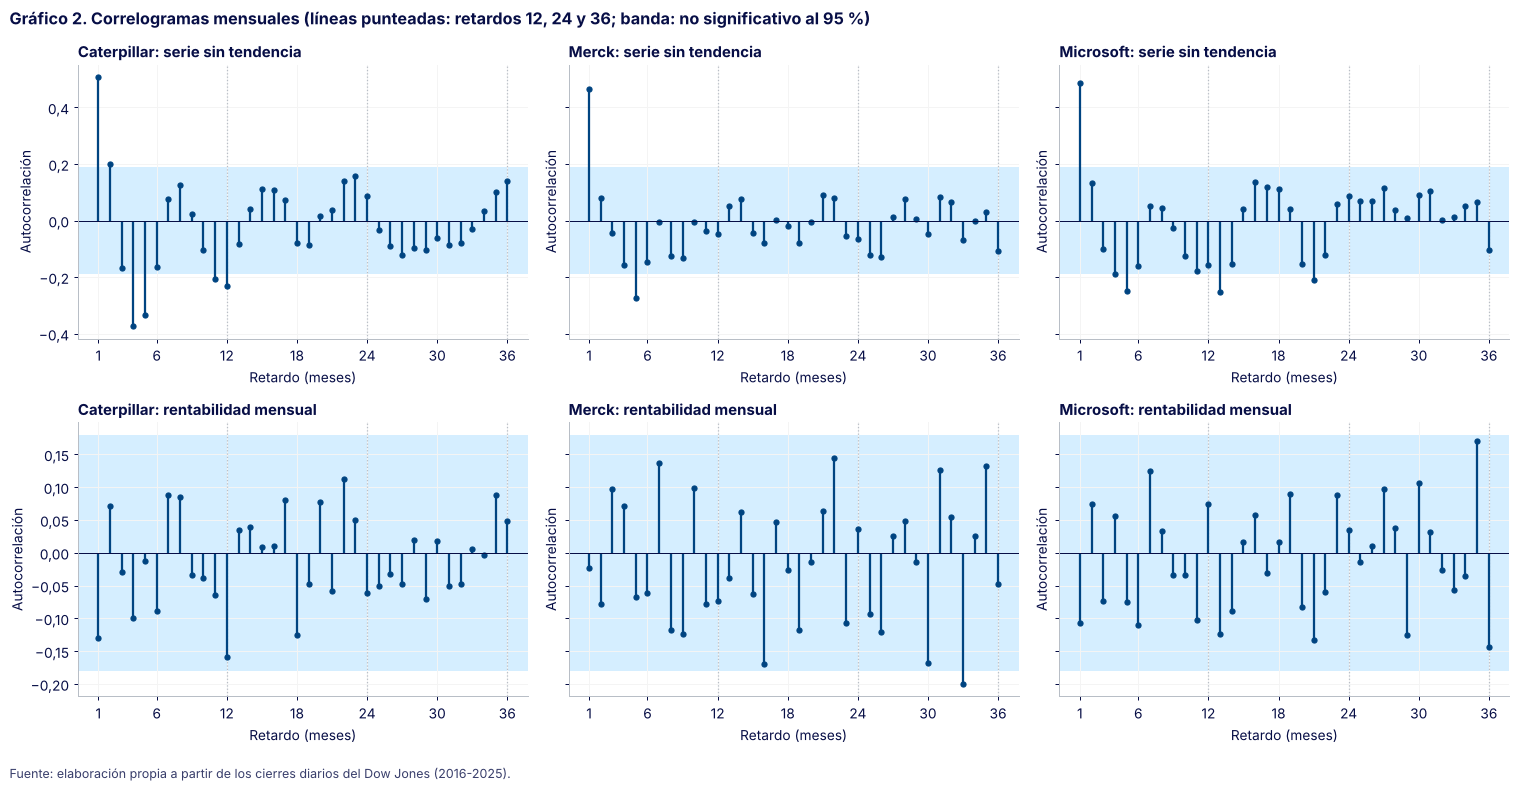

In [ ]:
def dibujar_correlograma(ax, valores, n, titulo):
    retardos = np.arange(1, len(valores))
    banda = 1.96 / np.sqrt(n)
    ax.axhspan(-banda, banda, color=CIELO, alpha=0.25, lw=0)
    for anual in (12, 24, 36):
        ax.axvline(anual, color=GRIS, lw=1, ls=":")
    ax.vlines(retardos, 0, valores[1:], color=PRINCIPAL, lw=1.8)
    ax.plot(retardos, valores[1:], "o", ms=4, color=PRINCIPAL)
    ax.axhline(0, color=MARINO, lw=0.8)
    ax.set_xticks([1, 6, 12, 18, 24, 30, 36])
    ax.set_xlabel("Retardo (meses)")
    ax.set_ylabel("Autocorrelación")
    ax.set_title(titulo)


fig, ejes = plt.subplots(2, 3, figsize=(17, 8.5), sharey="row")
for col, t in enumerate(ACTIVOS):
    dibujar_correlograma(ejes[0, col], acf(serie_sin_tendencia[t], nlags=RETARDOS_ACF, fft=True),
                         len(serie_sin_tendencia[t]), f"{ACTIVOS[t]}: serie sin tendencia")
    dibujar_correlograma(ejes[1, col], acf(rent_mes[t], nlags=RETARDOS_ACF, fft=True),
                         len(rent_mes[t]), f"{ACTIVOS[t]}: rentabilidad mensual")
fig.suptitle("Gráfico 2. Correlogramas mensuales (líneas punteadas: retardos 12, 24 y 36; banda: no significativo al 95 %)",
             x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "descomposicion_02_correlogramas_periodo")

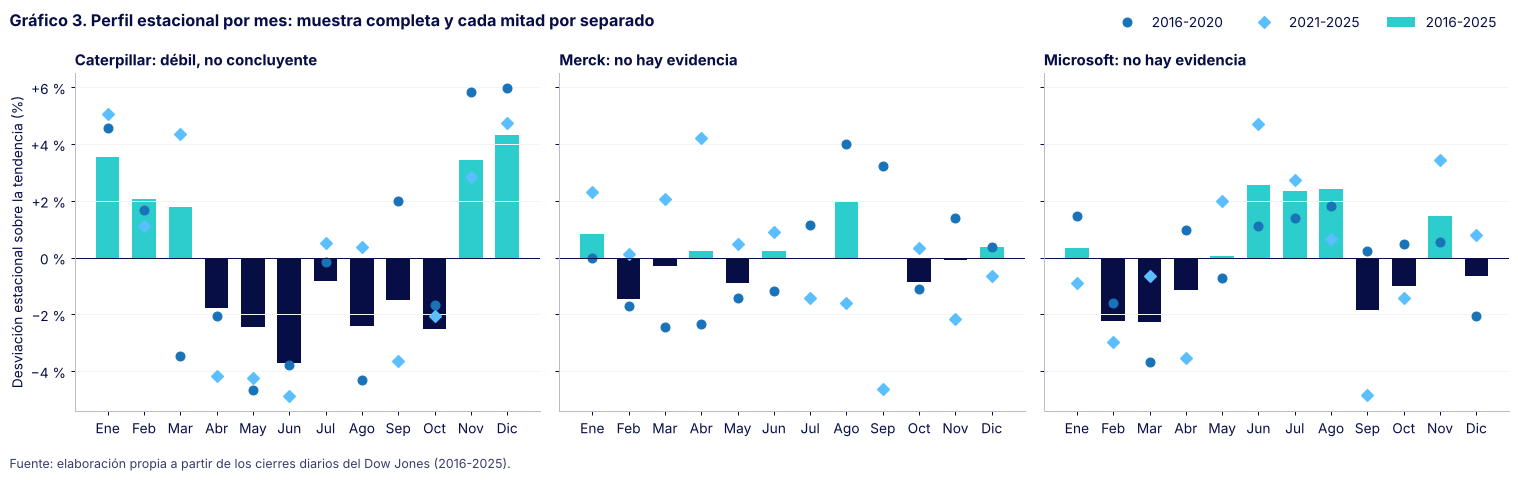

In [ ]:
# Perfil estacional: índice de cada mes del calendario en toda la muestra y en cada mitad
NOMBRES_MES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
fig, ejes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, t in zip(ejes, ACTIVOS):
    base = 1 if MODELO[t] == "multiplicative" else 0
    total = indices_estacionales(precios_mes[t], MODELO[t]) - base
    ax.bar(range(12), total, color=np.where(total >= 0, AGUAMARINA, MARINO), width=0.65, label="2016-2025")
    for periodo, marcador, color in [(("2016", "2020"), "o", MEDIO), (("2021", "2025"), "D", CIELO)]:
        parcial = indices_estacionales(precios_mes[t][periodo[0]:periodo[1]], MODELO[t]) - base
        ax.plot(range(12), parcial, marcador, color=color, ms=7, label=f"{periodo[0]}-{periodo[1]}")
    ax.axhline(0, color=MARINO, lw=0.8)
    ax.set_xticks(range(12), NOMBRES_MES)
    ax.grid(axis="x", visible=False)
    formato_eje_pct(ax, decimales=0, signo=True)
    veredicto = evidencia.loc[t, "veredicto"].lower()
    ax.set_title(f"{ACTIVOS[t]}: {veredicto}")
ejes[0].set_ylabel("Desviación estacional sobre la tendencia (%)")
manejadores, etiquetas = ejes[0].get_legend_handles_labels()
fig.legend(manejadores, etiquetas, loc="upper right", bbox_to_anchor=(0.99, 1.0), ncol=3)
fig.suptitle("Gráfico 3. Perfil estacional por mes: muestra completa y cada mitad por separado", x=0.01, ha="left")
plt.tight_layout()
cerrar_grafico(fig, "descomposicion_03_perfil_estacional")

**Resultado: el periodo es de 12 meses en los tres activos, pero en ninguno hay evidencia sólida de estacionalidad anual.**

**Periodos descartados**

- **Semanal (5 sesiones).** La rentabilidad diaria no cambia según el día de la semana (Kruskal-Wallis p = 0,85 en CAT, 0,35 en MRK y 0,84 en MSFT), y la autocorrelación en el retardo 5 (0,006; 0,023; 0,017) queda dentro de la banda de ± 0,039.
- **Trimestral u otros.** En el gráfico 2 no hay autocorrelaciones positivas y significativas en los retardos 3 o 6. La única autocorrelación grande de la serie sin tendencia es la del retardo 1 (≈ 0,5 en los tres activos), que indica persistencia (una desviación respecto a la tendencia dura varios meses), no estacionalidad.

**Periodo anual (12 meses): resultado de cada comprobación**

| | CAT | MRK | MSFT |
|---|---|---|---|
| Autocorrelación en el retardo 12 (sin tendencia / rentabilidad) | −0,23 / −0,16 | −0,05 / −0,07 | −0,16 / +0,07 |
| Kruskal-Wallis por mes (p) | 0,37 | 0,40 | 0,21 |
| Estabilidad entre mitades (ρ; p) | +0,66; 0,018 | −0,81; 0,001 | +0,20; 0,527 |
| Fuerza estacional F_S | 0,11 | 0,03 | 0,11 |
| Veredicto | Débil, no concluyente | No hay evidencia | No hay evidencia |

- Ningún activo tiene una autocorrelación **positiva** y significativa en los retardos 12, 24 o 36, que es lo que dejaría una estacionalidad anual. En Caterpillar la del retardo 12 es incluso negativa y significativa (−0,23), lo contrario de lo que se esperaría.
- Ningún mes tiene una rentabilidad distinta de la de los demás (todos los p > 0,2), y la fuerza estacional es muy baja en los tres (0,03 a 0,11).
- **Caterpillar** es el único activo cuyo perfil se repite en las dos mitades de la muestra (ρ = 0,66; p = 0,018): está por encima de la tendencia de noviembre a marzo y por debajo de abril a octubre. Es la única señal a favor, y las otras tres comprobaciones la contradicen, por eso se considera *débil, no concluyente*.
- En **Merck** el patrón se **invierte** entre las dos mitades (ρ = −0,81): los meses que estaban por encima de la tendencia en 2016-2020 están por debajo en 2021-2025. Es una prueba de que su "estacionalidad" es ruido.

**Por qué se mantiene el periodo 12.** Es el periodo que corresponde a la frecuencia mensual. Además, la muestra tiene 10 ciclos completos (cada índice estacional es la media de 9 valores), suficientes para que la descomposición se pueda calcular, aunque no para detectar efectos estacionales pequeños. En Merck y Microsoft el panel de estacionalidad del gráfico debe leerse como el tamaño del ruido que deja el promedio por meses, no como un patrón real.

## 4. Descomposición de cada activo

Cada gráfico tiene cuatro paneles: serie original, tendencia, estacionalidad y residuo. En el modelo multiplicativo la estacionalidad y el residuo son factores alrededor de 1; para que se lean mejor se muestran como **desviación porcentual** ($S_t - 1$ y $R_t - 1$). Los paneles de estacionalidad y residuo comparten la escala vertical para que se pueda comparar su tamaño. Los seis primeros y los seis últimos meses no tienen tendencia ni residuo, porque la media móvil centrada de 12 meses no puede calcularse en los extremos.

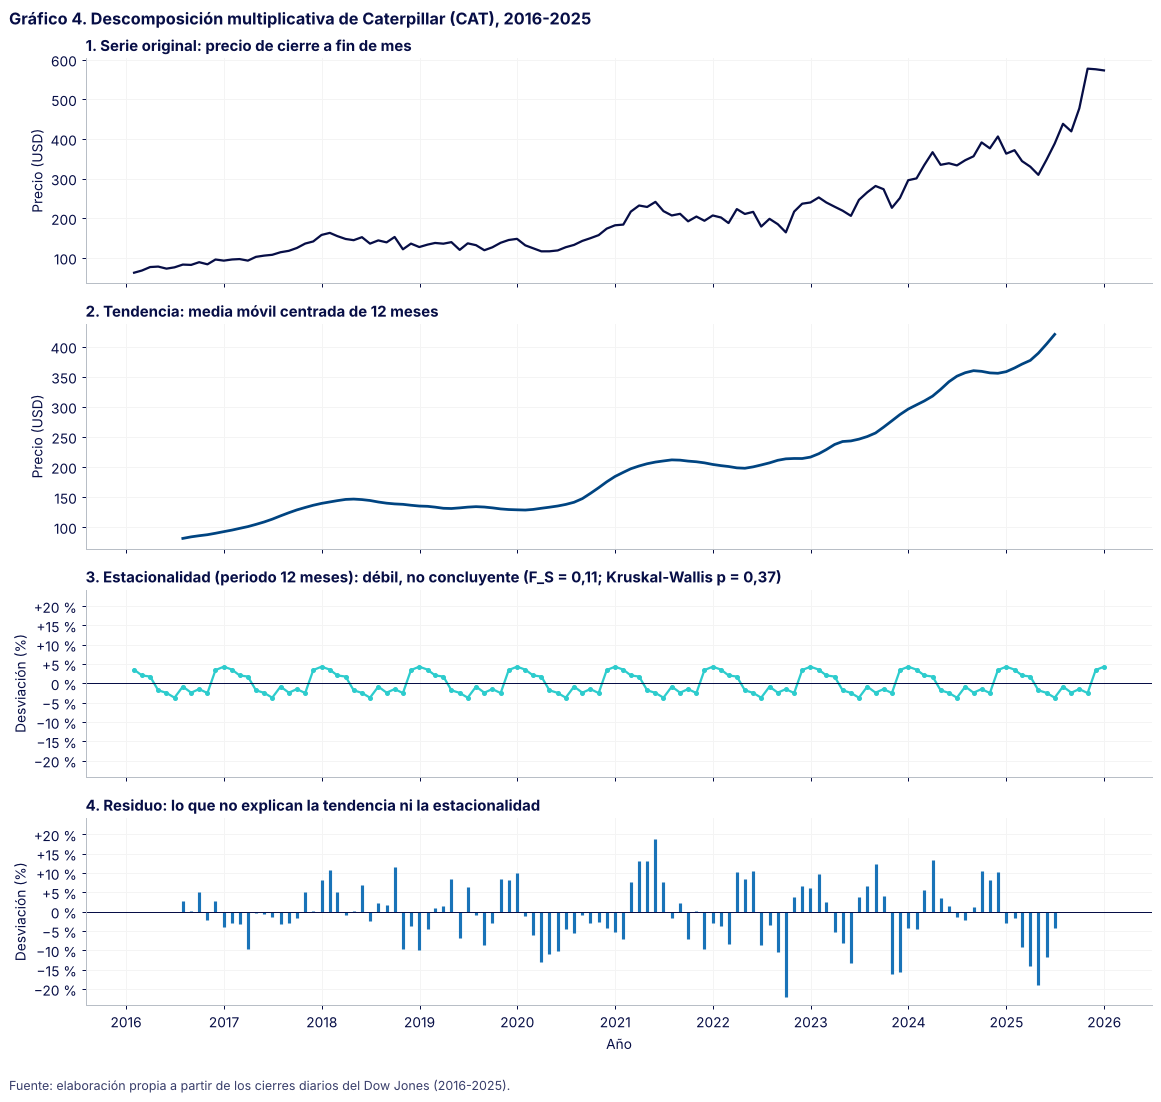

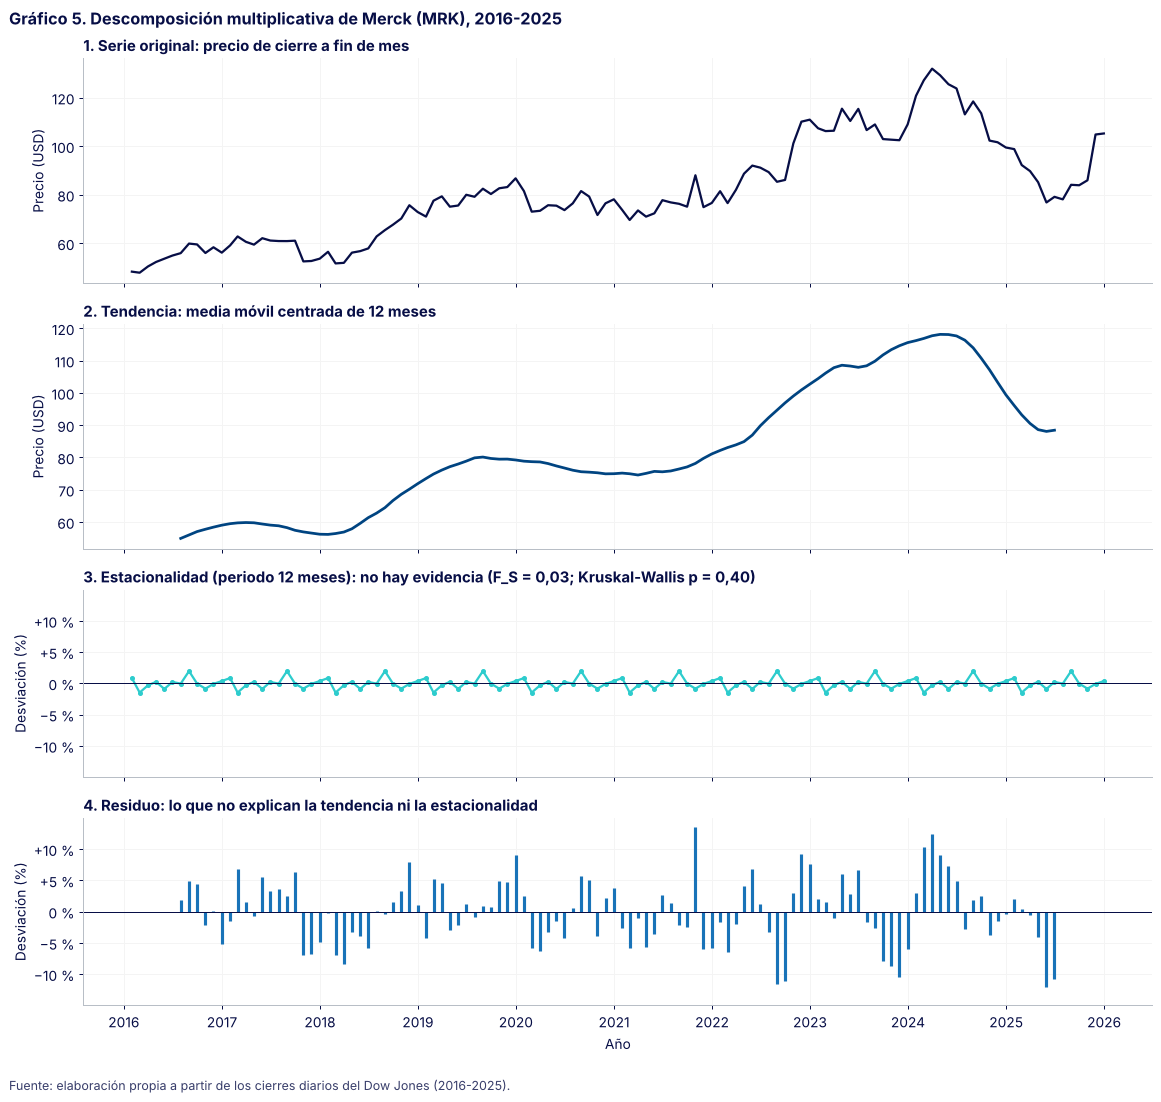

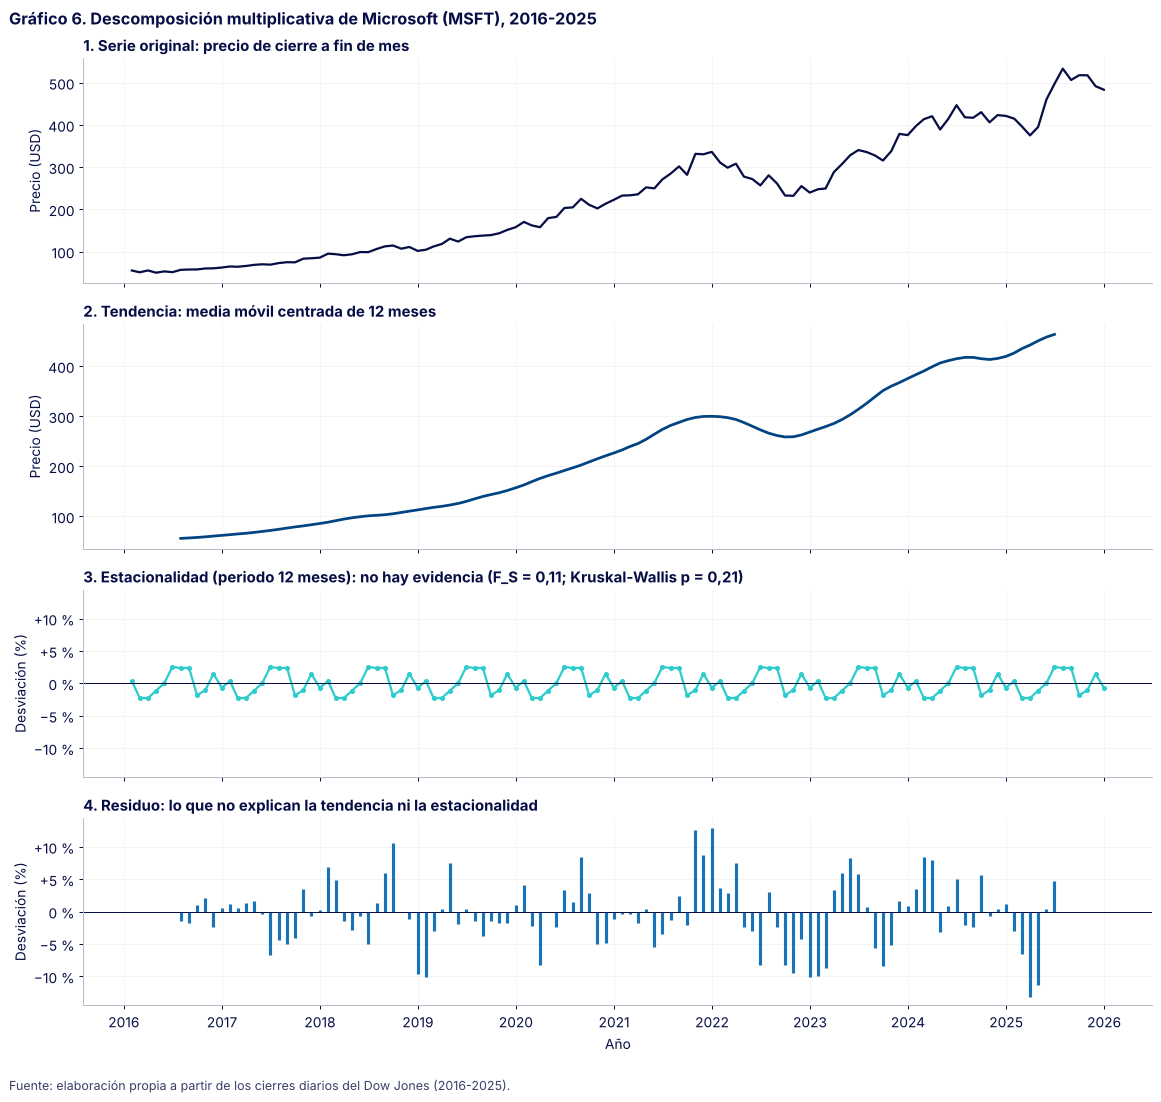

In [ ]:
def grafico_descomposicion(t, numero):
    d = descomposiciones[t]
    multiplicativo = MODELO[t] == "multiplicative"
    estacional = d.seasonal - 1 if multiplicativo else d.seasonal
    residuo = d.resid - 1 if multiplicativo else d.resid
    ev = evidencia.loc[t]
    nombre_modelo = "multiplicativa" if multiplicativo else "aditiva"

    fig, ejes = plt.subplots(4, 1, figsize=(13, 12), sharex=True, gridspec_kw={"height_ratios": [1.2, 1.2, 1, 1]})
    ejes[0].plot(d.observed, color=MARINO, lw=1.8)
    ejes[0].set_ylabel("Precio (USD)")
    ejes[0].set_title("1. Serie original: precio de cierre a fin de mes")

    ejes[1].plot(d.trend, color=PRINCIPAL, lw=2.2)
    ejes[1].set_ylabel("Precio (USD)")
    ejes[1].set_title("2. Tendencia: media móvil centrada de 12 meses")

    ejes[2].plot(estacional, color=AGUAMARINA, lw=1.8, marker="o", ms=3)
    ejes[2].axhline(0, color=MARINO, lw=0.8)
    ejes[2].set_title(f"3. Estacionalidad (periodo 12 meses): {ev['veredicto'].lower()} "
                      f"(F_S = {fmt_es(ev['fuerza_estacional_FS'], 2)}; Kruskal-Wallis p = {fmt_es(ev['kruskal_mes_p'], 2)})")

    ejes[3].vlines(residuo.index, 0, residuo, color=MEDIO, lw=2.5)
    ejes[3].axhline(0, color=MARINO, lw=0.8)
    ejes[3].set_title("4. Residuo: lo que no explican la tendencia ni la estacionalidad")

    limite = np.nanmax(np.abs(np.concatenate([estacional.to_numpy(), residuo.dropna().to_numpy()]))) * 1.1
    for ax in ejes[2:]:
        ax.set_ylim(-limite, limite)
        if multiplicativo:
            formato_eje_pct(ax, decimales=0, signo=True)
            ax.set_ylabel("Desviación (%)")
        else:
            ax.set_ylabel("USD")
    eje_anios(ejes[-1])
    ejes[-1].set_xlabel("Año")
    fig.suptitle(f"Gráfico {numero}. Descomposición {nombre_modelo} de {ACTIVOS[t]} ({t}), 2016-2025",
                 x=0.01, ha="left")
    plt.tight_layout()
    cerrar_grafico(fig, f"descomposicion_{numero:02d}_{t.lower()}")


for numero, t in enumerate(ACTIVOS, start=4):
    grafico_descomposicion(t, numero)

## 5. Diagnóstico del residuo

Si la descomposición recoge toda la estructura de la serie, el residuo debería parecerse a ruido blanco. Se mide:

- **Dispersión:** la desviación típica del residuo, en porcentaje (multiplicativo) o en USD (aditivo).
- **Autocorrelación:** la del retardo 1 y el test de Ljung-Box con 12 retardos. Si p < 0,05, al residuo le queda estructura temporal.
- **Meses más extremos:** el signo y la fecha de los residuos más grandes en valor absoluto.
- **Dispersión por año:** para ver si el residuo es más grande en unos periodos que en otros.

El test de Ljung-Box se calcula directamente con su fórmula, $Q = n(n+2)\sum_{k=1}^{h} \hat\rho_k^2/(n-k)$, que bajo la hipótesis de ruido blanco sigue una $\chi^2_h$. Así el resultado no depende de la versión de statsmodels.

In [ ]:
def ljung_box(serie, retardos):
    x = serie.dropna().to_numpy()
    n = len(x)
    rho = acf(x, nlags=retardos, fft=True)[1:]
    q = n * (n + 2) * np.sum(rho ** 2 / (n - np.arange(1, retardos + 1)))
    return q, stats.chi2.sf(q, retardos)


diagnostico, extremos = {}, {}
for t in ACTIVOS:
    d = descomposiciones[t]
    residuo = (d.resid - 1 if MODELO[t] == "multiplicative" else d.resid).dropna()
    q, p = ljung_box(residuo, RETARDOS_LJUNG_BOX)
    diagnostico[t] = {"n_residuos": len(residuo), "desv_tipica": residuo.std(),
                      "acf_retardo_1": acf(residuo, nlags=1, fft=True)[1],
                      "ljung_box_Q": q, "ljung_box_p": p}
    extremos[t] = residuo.reindex(residuo.abs().sort_values(ascending=False).index[:5])
    print(f"{t}: desviación típica del residuo por año")
    print(residuo.groupby(residuo.index.year).std().round(4).to_string())
    print()

diagnostico = pd.DataFrame(diagnostico).T
print("Diagnóstico del residuo (multiplicativo: en tanto por uno):")
print(diagnostico.astype(float).round(4).to_string())
for t in ACTIVOS:
    print(f"\n{t}: cinco residuos más extremos")
    print(extremos[t].round(4).to_string())

CAT: desviación típica del residuo por año
date
2016    0.0339
2017    0.0443
2018    0.0697
2019    0.0654
2020    0.0389
2021    0.0915
2022    0.1017
2023    0.0989
2024    0.0595
2025    0.0645

MRK: desviación típica del residuo por año
date
2016    0.0392
2017    0.0489
2018    0.0465
2019    0.0397
2020    0.0430
2021    0.0552
2022    0.0695
2023    0.0572
2024    0.0530
2025    0.0593

MSFT: desviación típica del residuo por año
date
2016    0.0175
2017    0.0319
2018    0.0560
2019    0.0403
2020    0.0466
2021    0.0615
2022    0.0581
2023    0.0636
2024    0.0399
2025    0.0686

Diagnóstico del residuo (multiplicativo: en tanto por uno):
      n_residuos  desv_tipica  acf_retardo_1  ljung_box_Q  ljung_box_p
CAT        108.0       0.0779         0.4884      96.4674          0.0
MRK        108.0       0.0534         0.4811      46.1910          0.0
MSFT       108.0       0.0518         0.5041      66.8156          0.0

CAT: cinco residuos más extremos
date
2022-09-30   -0.220

In [ ]:
# Evolución de la tendencia: crecimiento total, tasa anual compuesta y máximos y mínimos
evolucion = {}
for t in ACTIVOS:
    tendencia = descomposiciones[t].trend.dropna()
    anios = (tendencia.index[-1] - tendencia.index[0]).days / 365.25
    evolucion[t] = {
        "inicio": f"{tendencia.index[0]:%Y-%m}", "tendencia_inicio": tendencia.iloc[0],
        "fin": f"{tendencia.index[-1]:%Y-%m}", "tendencia_fin": tendencia.iloc[-1],
        "multiplica_por": tendencia.iloc[-1] / tendencia.iloc[0],
        "crecimiento_anual": (tendencia.iloc[-1] / tendencia.iloc[0]) ** (1 / anios) - 1,
        "maximo": f"{tendencia.idxmax():%Y-%m}", "tendencia_max": tendencia.max(),
        "caida_desde_max": tendencia.iloc[-1] / tendencia.max() - 1,
    }
    print(f"{t}: tendencia media por año (USD)")
    print(tendencia.groupby(tendencia.index.year).mean().round(1).to_string())
    print()
evolucion = pd.DataFrame(evolucion).T
print(evolucion.to_string())

CAT: tendencia media por año (USD)
date
2016     86.7
2017    116.6
2018    141.5
2019    131.9
2020    147.1
2021    205.5
2022    206.6
2023    254.5
2024    341.6
2025    387.9

MRK: tendencia media por año (USD)
date
2016     57.2
2017     58.5
2018     62.7
2019     78.0
2020     76.7
2021     76.6
2022     91.4
2023    109.7
2024    113.0
2025     90.8

MSFT: tendencia media por año (USD)
date
2016     59.0
2017     73.9
2018    101.3
2019    134.0
2020    194.9
2021    272.5
2022    275.6
2023    322.3
2024    408.5
2025    445.8

       inicio tendencia_inicio      fin tendencia_fin multiplica_por crecimiento_anual   maximo tendencia_max caida_desde_max
CAT   2016-07        81.205833  2025-06     420.47875       5.177938          0.202575  2025-06     420.47875             0.0
MRK   2016-07        54.930025  2025-06     88.448334         1.6102           0.05489  2024-04    118.132499       -0.251279
MSFT  2016-07        56.173333  2025-06    463.415835       8.249748          

## 6. Tabla resumen

In [ ]:
def justificar_modelo(t):
    e = eleccion_modelo.loc[t]
    return (f"{e['decision']}. Amplitud frente a nivel: ρ = {fmt_es(e['rho_amplitud_nivel'], 2)} "
            f"(p {fmt_p(e['p_amplitud_nivel'])}); residuo aditivo frente a tendencia: "
            f"ρ = {fmt_es(e['rho_resid_aditivo'], 2)} (p {fmt_p(e['p_resid_aditivo'])}), "
            f"multiplicativo: ρ = {fmt_es(e['rho_resid_multiplicativo'], 2)} (p {fmt_p(e['p_resid_multiplicativo'])}). "
            f"Precios > 0 (mínimo {fmt_es(e['precio_min_usd'], 2)} USD).")


def justificar_periodo(t):
    ev, sem = evidencia.loc[t], semanal.loc[t]
    return (f"Datos mensuales: 12 meses por ciclo, {anios_completos} ciclos completos. "
            f"Sin efecto semanal (Kruskal-Wallis por día p = {fmt_es(sem['kruskal_dia_p'], 2)}). "
            f"Estacionalidad anual: {ev['veredicto'].lower()} (Kruskal-Wallis por mes p = {fmt_es(ev['kruskal_mes_p'], 2)}; "
            f"estabilidad entre mitades ρ = {fmt_es(ev['estabilidad_rho'], 2)}, p {fmt_p(ev['estabilidad_p'])}; "
            f"F_S = {fmt_es(ev['fuerza_estacional_FS'], 2)}).")


resumen = pd.DataFrame({
    "Activo": [f"{ACTIVOS[t]} ({t})" for t in ACTIVOS],
    "Modelo": ["Multiplicativo" if MODELO[t] == "multiplicative" else "Aditivo" for t in ACTIVOS],
    "Periodo": [f"{PERIODO} meses" for _ in ACTIVOS],
    "Estacionalidad": [evidencia.loc[t, "veredicto"] for t in ACTIVOS],
    "Justificación del modelo": [justificar_modelo(t) for t in ACTIVOS],
    "Justificación del periodo": [justificar_periodo(t) for t in ACTIVOS],
})
resumen.to_csv(RUTA_RESULTADOS / "descomposicion_resumen.csv", index=False, encoding="utf-8-sig")
with pd.option_context("display.max_colwidth", None):
    print(resumen.to_string(index=False))
print(f"\nGuardado: {RUTA_RESULTADOS / 'descomposicion_resumen.csv'}")

           Activo         Modelo  Periodo        Estacionalidad                                                                                                                                                                                                                                     Justificación del modelo                                                                                                                                                                                                                                 Justificación del periodo
Caterpillar (CAT) Multiplicativo 12 meses Débil, no concluyente Multiplicativo: los dos criterios indican que la amplitud crece con el nivel. Amplitud frente a nivel: ρ = 0,95 (p < 0,001); residuo aditivo frente a tendencia: ρ = 0,50 (p < 0,001), multiplicativo: ρ = 0,27 (p = 0,005). Precios > 0 (mínimo 62,24 USD). Datos mensuales: 12 meses por ciclo, 10 ciclos completos. Sin efecto semanal (Kruskal-Wallis por día p = 0,85). Esta

| Activo | Modelo | Periodo | Justificación del modelo | Justificación del periodo |
|---|---|---|---|---|
| Caterpillar (CAT) | Multiplicativo | 12 meses | La amplitud en USD crece con el nivel (ρ = 0,95; p < 0,001). El residuo aditivo depende de la tendencia (ρ = 0,50), el multiplicativo mucho menos (ρ = 0,27). Precio > 0. | Frecuencia mensual, 10 ciclos completos; sin efecto semanal (p = 0,85). Estacionalidad débil, no concluyente: patrón estable entre mitades (ρ = 0,66; p = 0,018), pero Kruskal-Wallis p = 0,37, F_S = 0,11 y autocorrelación negativa en el retardo 12. |
| Merck (MRK) | Multiplicativo | 12 meses | La amplitud crece con el nivel con menos fuerza (ρ = 0,70; p = 0,025). El residuo aditivo depende de la tendencia (ρ = 0,33; p = 0,001) y el multiplicativo no (ρ = 0,14; p = 0,139). Precio > 0. | Frecuencia mensual, 10 ciclos completos; sin efecto semanal (p = 0,35). No hay evidencia de estacionalidad: Kruskal-Wallis p = 0,40, F_S = 0,03 y el patrón se invierte entre mitades (ρ = −0,81). |
| Microsoft (MSFT) | Multiplicativo | 12 meses | La amplitud crece con el nivel (ρ = 0,94; p < 0,001). El residuo aditivo depende de la tendencia (ρ = 0,42), el multiplicativo menos (ρ = 0,26). Precio > 0. | Frecuencia mensual, 10 ciclos completos; sin efecto semanal (p = 0,84). No hay evidencia de estacionalidad: Kruskal-Wallis p = 0,21, F_S = 0,11 y patrón no estable entre mitades (ρ = 0,20; p = 0,527). |

La misma tabla, con los valores calculados por el código, se guarda en `Datos/Transformados/descomposicion_resumen.csv`.

## 7. Interpretación de cada activo

### 7.1 Caterpillar (CAT) — gráfico 4

**Tendencia.** La tendencia pasa de 81,2 USD (julio de 2016) a 420,5 USD (junio de 2025): se multiplica por 5,2, un crecimiento compuesto del 20,3 % anual. El avance no es continuo, sino que alterna subidas y mesetas:

- **2016-2018:** sube hasta 146,6 USD (abril de 2018).
- **Mediados de 2018 a 2020:** se estanca y baja ligeramente hasta 128,4 USD (enero de 2020). Este tramo incluye las ventas de finales de 2018.
- **2020-2021:** sube con fuerza hasta 211,8 USD (julio de 2021).
- **2021-2022:** meseta, con un mínimo de 197,9 USD en abril de 2022, coincidiendo con la subida de tipos.
- **Desde finales de 2022:** acelera hasta el final de la serie de tendencia (420,5 USD), que es su máximo.

El precio siguió subiendo después (577 USD en octubre de 2025), pero esos meses quedan fuera de la media móvil.

**Estacionalidad.** El perfil estimado sitúa el precio por encima de la tendencia de noviembre a marzo (diciembre +4,3 %, enero +3,6 %, noviembre +3,4 %) y por debajo de abril a octubre (junio −3,7 %). Es el único de los tres activos cuyo perfil se parece en 2016-2020 y en 2021-2025 (ρ = 0,66; p = 0,018). Aun así:

- Ningún mes tiene una rentabilidad significativamente distinta (Kruskal-Wallis p = 0,37).
- La fuerza estacional es baja (F_S = 0,11).
- Las oscilaciones estacionales (± 4 %) son la mitad de la desviación típica del residuo (7,8 %).
- La autocorrelación en el retardo 12 es negativa (−0,23) y no positiva.

Por eso la estacionalidad se califica como **débil y no concluyente**: hay un indicio, pero no permite afirmar que exista un patrón anual.

**Residuo.** Es el más disperso de los tres activos: desviación típica del 7,8 %, y el 18 % de los meses se separa más de un 10 % de la tendencia. Los meses más extremos son:

- Septiembre de 2022: −22,0 %, al final del episodio de subida de tipos.
- Abril de 2025: −19,1 %, el mes del episodio de aranceles.
- Mayo de 2021: +18,7 %.
- Octubre y noviembre de 2023: −16,2 % y −15,6 %.

La dispersión del residuo cambia mucho con los años: del 3,4 % en 2016 al 9-10 % en 2021-2023. El residuo no es ruido blanco (autocorrelación de 0,49 en el retardo 1; Ljung-Box Q = 96,5; p < 0,001). Tiene rachas de hasta 13 meses con el mismo signo, que corresponden a oscilaciones de medio plazo que la media móvil de 12 meses no recoge.

**Limitaciones y qué no se puede concluir**

- La tendencia es una media móvil: describe el pasado y reacciona con retraso a los cambios de dirección, así que no sirve para predecir.
- No hay tendencia para los seis últimos meses, justo los de mayor subida.
- La estacionalidad no es lo bastante sólida para concluir que convenga comprar o vender en determinados meses.
- Que un residuo extremo coincida con un episodio de mercado no demuestra que ese episodio lo causara.

### 7.2 Merck (MRK) — gráfico 5

**Tendencia.** Es la de menor crecimiento: de 54,9 USD (julio de 2016) a 88,4 USD (junio de 2025), es decir, se multiplica por 1,6 (un 5,5 % anual compuesto). Es la única de las tres que termina en **descenso**. Por tramos:

- **2016-2018:** lateral, entre 55 y 60 USD.
- **2018-2019:** sube hasta 80,1 USD (agosto de 2019).
- **2019-2021:** se mantiene lateral y baja ligeramente hasta 74,6 USD (marzo de 2021).
- **2021-2024:** sube hasta su máximo de 118,1 USD (abril de 2024). En 2022 siguió subiendo (de 76,6 a 91,4 USD de media anual), mientras que la de Microsoft bajó.
- **Desde abril de 2024:** cae un 25 % hasta 88,1 USD (mayo de 2025).

El precio se recuperó a final de año (105 USD en noviembre y diciembre de 2025), pero esos meses quedan fuera de la tendencia. La descomposición no permite saber si la caída ha terminado.

**Estacionalidad.** No hay estacionalidad:

- La fuerza estacional es la más baja de los tres activos (F_S = 0,03).
- Los factores estacionales solo van de −1,5 % (febrero) a +2,0 % (agosto).
- Ningún mes tiene una rentabilidad distinta (Kruskal-Wallis p = 0,40).
- El perfil se **invierte** entre 2016-2020 y 2021-2025 (ρ = −0,81; p = 0,001).

El panel 3 del gráfico es el ruido que queda al promediar 9 valores por mes y no debe interpretarse como un patrón.

**Residuo.** Desviación típica del 5,3 %; solo el 6,7 % de los meses se separa más de un 10 % de la tendencia. Los meses más extremos son octubre de 2021 (+13,6 %), marzo de 2024 (+12,4 %), mayo de 2025 (−12,0 %) y agosto y septiembre de 2022 (−11,6 % y −11,1 %). Se ven dos rachas:

- **Primera mitad de 2024:** residuos positivos. El precio subió más rápido de lo que la media móvil podía seguir, justo antes del máximo de la tendencia.
- **Primavera de 2025:** residuos negativos, durante la caída.

Es el residuo con menos estructura de los tres (Ljung-Box Q = 46,2), pero sigue sin ser ruido blanco (autocorrelación de 0,48 en el retardo 1; p < 0,001). Su dispersión sube del 3,9 % en 2016 al 6,9 % en 2022.

**Limitaciones y qué no se puede concluir**

- La elección del modelo multiplicativo se apoya sobre todo en el criterio del residuo, porque el rango de precios es estrecho y 2025 se sale del patrón amplitud-nivel.
- La media móvil suaviza y retrasa los cambios de dirección: el máximo de la tendencia (118,1 USD) es más bajo que el del precio mensual (131,95 USD).
- No se puede afirmar que la caída de 2024-2025 sea un cambio de tendencia duradero.

### 7.3 Microsoft (MSFT) — gráfico 6

**Tendencia.** Es la de mayor crecimiento y la más regular: de 56,2 USD (julio de 2016) a 463,4 USD (junio de 2025), es decir, se multiplica por 8,2 (un 26,7 % anual compuesto). Por tramos:

- **2016-2021:** sube de forma casi continua, cada vez más deprisa, hasta 299,9 USD (diciembre de 2021).
- **2022:** su única caída, un 13,7 % hasta 258,7 USD (septiembre de 2022), en el periodo de subida de tipos.
- **Desde finales de 2022:** retoma la subida, con una breve meseta en torno a 415 USD entre mediados de 2024 y comienzos de 2025, y termina en su máximo.

El precio llegó a 533,5 USD en julio de 2025 y bajó a 483,6 USD en diciembre, pero esos meses quedan fuera de la tendencia.

**Estacionalidad.** No hay evidencia:

- La fuerza estacional es baja (F_S = 0,11).
- Ningún mes tiene una rentabilidad distinta (Kruskal-Wallis p = 0,21).
- El perfil de 2016-2020 no se parece al de 2021-2025 (ρ = 0,20; p = 0,527).

El perfil estimado (junio a agosto, alrededor de +2,5 %; febrero y marzo, alrededor de −2,2 %) cambia de una mitad a otra (gráfico 3), así que no debe interpretarse como un efecto de calendario.

**Residuo.** Es el menos disperso de los tres: desviación típica del 5,2 %, y solo el 5,8 % de los meses se separa más de un 10 % de la tendencia. La dispersión crece con el tiempo: del 1,8 % en 2016 al 6,9 % en 2025. Los meses más extremos son:

- Octubre y diciembre de 2021: +12,6 % y +12,9 %. El precio estaba muy por encima de la tendencia justo antes de la caída de 2022.
- Marzo y abril de 2025: −13,1 % y −11,3 %. Abril coincide con el episodio de aranceles.
- Septiembre de 2018: +10,6 %.

Entre finales de 2022 y comienzos de 2023 el residuo es negativo varios meses seguidos. El residuo no es ruido blanco (autocorrelación de 0,50 en el retardo 1; Ljung-Box Q = 66,8; p < 0,001).

**Limitaciones y qué no se puede concluir**

- La tendencia no permite extrapolar el crecimiento del 26,7 % anual: es una media móvil del pasado.
- La caída de 2022 aparece suavizada y con retraso respecto al precio.
- Que el residuo esté autocorrelacionado indica que hay ciclos de medio plazo que esta descomposición no separa.

## 8. Conclusión comparativa y limitaciones

**Comparación entre los tres activos**

| | Caterpillar | Merck | Microsoft |
|---|---|---|---|
| Modelo | Multiplicativo (evidencia fuerte) | Multiplicativo (evidencia más débil) | Multiplicativo (evidencia fuerte) |
| Tendencia jul. 2016 → jun. 2025 | ×5,2 (20,3 % anual) | ×1,6 (5,5 % anual) | ×8,2 (26,7 % anual) |
| Dirección al final de la tendencia | En su máximo | Cae un 25 % desde abril de 2024 | En su máximo |
| Estacionalidad (periodo 12) | Débil, no concluyente (F_S = 0,11) | No hay evidencia (F_S = 0,03) | No hay evidencia (F_S = 0,11) |
| Desviación típica del residuo | 7,8 % | 5,3 % | 5,2 % |
| Autocorrelación del residuo (retardo 1) | 0,49 | 0,48 | 0,50 |

**Lo que comparten**

- En los tres activos la **tendencia** domina la serie y su amplitud es proporcional al nivel, así que el modelo es multiplicativo.
- Ninguno tiene **estacionalidad anual** robusta.
- En los tres el residuo conserva estructura: la descomposición clásica deja las oscilaciones de medio plazo (ciclo) dentro del residuo.

**Lo que los diferencia**

- **Crecimiento de la tendencia:** Microsoft es la que más crece y de forma más regular. Caterpillar crece mucho, pero a saltos (mesetas en 2018-2020 y en 2021-2022) y con el residuo más grande de los tres, lo que encaja con una acción industrial cíclica. Merck crece poco y es la única con la tendencia bajando al final de la muestra.
- **Comportamiento en 2022:** la tendencia de Merck **subió** mientras la de Microsoft caía y la de Caterpillar se estancaba. Es un dato útil para la cartera: los tres activos no reaccionan igual en los mismos periodos.
- **Abril de 2025:** deja residuos negativos grandes en Caterpillar (−19,1 %) y Microsoft (−11,3 %). En Merck el residuo negativo más grande de ese año llega en mayo (−12,0 %).

**Consecuencias para el resto del proyecto**

- **Modelos:** como no hay estacionalidad significativa, no hace falta añadir términos estacionales (por ejemplo, un SARIMA con periodo 12). Basta con modelizar las rentabilidades logarítmicas, que eliminan la tendencia.
- **Uso de la descomposición:** sirve sobre todo para **describir** la evolución de cada activo, no para predecir.

**Limitaciones generales**

1. **Media móvil:** la tendencia pierde 6 meses en cada extremo (no hay tendencia para la primera mitad de 2016 ni para la segunda de 2025) y reacciona con retraso a los cambios de dirección.
2. **Estacionalidad constante:** `seasonal_decompose` supone que el patrón estacional es el mismo todos los años. Si se quisiera permitir que cambie, habría que usar STL (`statsmodels.tsa.seasonal.STL`). Aquí no se ha hecho porque no hay estacionalidad significativa que modelizar.
3. **Poca potencia:** con 10 años, cada índice estacional es la media de 9 valores, así que efectos estacionales pequeños (± 2-4 %) no se distinguen del ruido. *No encontrar evidencia no demuestra que la estacionalidad no exista.* Solo indica que, con estos datos, no se puede afirmar que exista.
4. **Residuo con estructura:** el residuo está autocorrelacionado y mezcla ciclo y ruido. Los p-valores de los contrastes que usan el residuo son, por tanto, aproximados.
5. **Un cierre por mes:** la serie mensual depende del cierre del último día de cada mes y no recoge lo que pasa dentro del mes.
6. **Ni causas ni predicciones:** la descomposición no identifica qué causó los movimientos (las coincidencias con episodios de mercado son solo eso, coincidencias) ni permite predecir.
7. **Datos:** el precio procede de dos fuentes (Yahoo Finance y un CSV). No se han detectado saltos en los cambios de fuente, pero no se ha comprobado si el cierre está ajustado por dividendos. Si no lo está, la tendencia mide la evolución del precio, no la rentabilidad total del accionista.

## 9. Comprobación de los criterios de aceptación

| Criterio | Dónde se cumple |
|---|---|
| **1. Descomposición de los tres activos** en tendencia, estacionalidad y residuo con `statsmodels` | Apartado 3, celda de evidencia anual (`seasonal_decompose` para cada activo) y apartado 4 |
| Componentes válidos | Apartado 1: sin valores ausentes, precios > 0, sin saltos en los cambios de fuente, 120 meses y 10 ciclos completos. El modelo multiplicativo solo se usa con precios > 0 (comprobado en `elegir_modelo`) |
| **2. Modelo aditivo o multiplicativo** elegido para cada activo y justificado | Apartado 2: dos criterios con regla de decisión explícita, gráfico 1 y texto con los resultados de cada activo. Sale multiplicativo en los tres por los datos, no por defecto, y Merck se señala como el caso con evidencia más débil |
| Compatibilidad matemática | Apartado 2, paso 0: precio mínimo > 0 en los tres |
| **3. Periodo** según la frecuencia y los patrones | Apartado 1 (por qué mensual y no diario) y apartado 3: se descarta el periodo semanal, se analiza el anual con correlogramas (gráfico 2), Kruskal-Wallis, estabilidad (gráfico 3) y F_S |
| Observaciones y ciclos suficientes | Apartado 1: 120 meses, 10 ciclos, 9 valores por índice estacional; la limitación de potencia se explica en el apartado 8 |
| No inventar estacionalidad | Apartado 3, con veredicto explícito: no hay evidencia en MRK ni en MSFT, y en CAT es débil y no concluyente. Se repite en el título de cada gráfico |
| **4. Un gráfico por activo con cuatro paneles** | Gráficos 4, 5 y 6, guardados en `Graficos/descomposicion_04_cat.png`, `descomposicion_05_mrk.png` y `descomposicion_06_msft.png`. Siguen la guía de CLAUDE.md (paleta BBVA, formato español, unidades y fuente) |
| **5. Interpretación de cada activo** (tendencia, estacionalidad, residuo, limitaciones) | Apartado 7, con las cifras de las salidas de los apartados 2 a 5 |
| **Entregable: tabla resumen** | Apartado 6 (generada por el código y guardada en `Datos/Transformados/descomposicion_resumen.csv`) |
| **Entregable: conclusión comparativa** | Apartado 8 |
| Reproducibilidad | Ruta relativa a la raíz del proyecto, parámetros al principio y sin aleatoriedad. Ejecutar con *Restart & Run All* |